In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



Todos los flujos monetarios se expresan en **millones de CLP reales**, excepto los parámetros que se indican explícitamente en CLP/kg o US$/kg.


In [2]:

# Proyecto
inversion_fija = 1850.0          # MM CLP
capital_trabajo = 220.0          # MM CLP
vida_util = 5                    # años
valor_salvamento = 180.0         # MM CLP, antes de impuestos

# Tributación y tasa de descuento
tasa_impuesto = 0.27
tmar_base = 0.12

# Producción
capacidad_kg = 2_400_000         # 2.400 toneladas/año
utilizacion_anio1 = 0.85
utilizacion_regimen = 1.00

# Ingresos
precio_fob_base = 3.80           # US$/kg
tipo_cambio_base = 1017.66       # CLP/US$

# Costos
costo_variable_base = 1650.0     # CLP/kg
costo_energia_base = 180.0       # CLP/kg, incluido en el costo variable
costos_fijos = 280.0             # MM CLP/año

# Depreciación lineal
depreciacion = inversion_fija / vida_util

print(f"Depreciación anual: {depreciacion:.4f} MM CLP")


Depreciación anual: 370.0000 MM CLP




El flujo operacional después de impuestos se calcula mediante:

\[ FCN_t=(Ingresos_t-Egresos_t)(1-t)+tD \]

donde \(D\) corresponde a la depreciación anual.

En el año 5 se agrega la recuperación del capital de trabajo y el valor de salvamento neto de impuesto.


In [3]:
def construir_fcn(
    precio_fob=precio_fob_base,
    tipo_cambio=tipo_cambio_base,
    multiplicador_volumen=1.0,
    multiplicador_energia=1.0
):
    """Construye el FCN desde t=0 hasta t=5, en MM CLP."""

    # Solo se modifica el componente energético de $180 CLP/kg.
    costo_energia = costo_energia_base * multiplicador_energia
    costo_variable = (
        costo_variable_base
        - costo_energia_base
        + costo_energia
    )

    volumen_anio1 = (
        capacidad_kg
        * utilizacion_anio1
        * multiplicador_volumen
    )

    volumen_regimen = (
        capacidad_kg
        * utilizacion_regimen
        * multiplicador_volumen
    )

    volumenes = [
        volumen_anio1,
        volumen_regimen,
        volumen_regimen,
        volumen_regimen,
        volumen_regimen
    ]

    # t = 0
    flujos = [-(inversion_fija + capital_trabajo)]

    for anio, volumen in enumerate(volumenes, start=1):

        ingresos = (
            volumen
            * precio_fob
            * tipo_cambio
            / 1_000_000
        )

        costo_variable_anual = (
            volumen
            * costo_variable
            / 1_000_000
        )

        fcn_operacional = (
            (ingresos - costo_variable_anual - costos_fijos)
            * (1 - tasa_impuesto)
            + tasa_impuesto * depreciacion
        )

        # Año 5: recuperación de WC + salvamento neto de impuesto
        if anio == 5:
            salvamento_neto = valor_salvamento * (1 - tasa_impuesto)
            fcn_operacional += capital_trabajo + salvamento_neto

        flujos.append(fcn_operacional)

    return np.array(flujos, dtype=float)


def calcular_van(flujos, tasa):
    """Calcula el VAN de una secuencia de flujos."""
    return sum(
        flujo / (1 + tasa) ** periodo
        for periodo, flujo in enumerate(flujos)
    )


## 4. Verificación del caso base


In [4]:


fcn_base = construir_fcn()
van_base = calcular_van(fcn_base, tmar_base)

tabla_fcn = pd.DataFrame({
    "Periodo": ["t=0", "2027", "2028", "2029", "2030", "2031"],
    "FCN (MM CLP)": fcn_base
})

display(tabla_fcn.round(4))

print(f"\nVAN base al 12% = {van_base:,.4f} MM CLP")


,Periodo,FCN (MM CLP)
0,t=0,-2070.0000
1,2027,3197.2172
2,2028,3779.8732
3,2029,3779.8732
4,2030,3779.8732
5,2031,4131.2732



VAN base al 12% = 11,234.7623 MM CLP



Se varía **una sola variable a la vez**, manteniendo las demás constantes.

Los niveles utilizados son:

\[-20\%,\;-10\%,\;0\%,\;+10\%,\;+20\%\]

Para la energía se modifica exclusivamente el componente de **$180 CLP/kg** incluido en el costo variable.

En el caso de la TMAR, una variación de \(+20\%\) implica:

\[12\%(1+0.20)=14.40\%.\]


In [6]:


variaciones = np.array([-0.20, -0.10, 0.00, 0.10, 0.20])

resultados = {
    "Precio FOB": [],
    "Tipo de cambio": [],
    "Volumen exportado": [],
    "Costo de energía": [],
    "TMAR": []
}

for variacion in variaciones:

    factor = 1 + variacion

    # Precio FOB
    fcn = construir_fcn(
        precio_fob=precio_fob_base * factor
    )
    resultados["Precio FOB"].append(
        calcular_van(fcn, tmar_base)
    )

    # Tipo de cambio
    fcn = construir_fcn(
        tipo_cambio=tipo_cambio_base * factor
    )
    resultados["Tipo de cambio"].append(
        calcular_van(fcn, tmar_base)
    )

    # Volumen
    fcn = construir_fcn(
        multiplicador_volumen=factor
    )
    resultados["Volumen exportado"].append(
        calcular_van(fcn, tmar_base)
    )

    # Energía: solo cambia el componente de 180 CLP/kg
    fcn = construir_fcn(
        multiplicador_energia=factor
    )
    resultados["Costo de energía"].append(
        calcular_van(fcn, tmar_base)
    )

    # TMAR
    tasa = tmar_base * factor
    resultados["TMAR"].append(
        calcular_van(fcn_base, tasa)
    )


tabla_sensibilidad = pd.DataFrame(
    resultados,
    index=["-20%", "-10%", "Base", "+10%", "+20%"]
)

display(tabla_sensibilidad.round(4))


,Precio FOB,Tipo de cambio,Volumen exportado,Costo de energía,TMAR
-20%,6531.6435,6531.6435,8538.3487,11453.6756,12096.9054
-10%,8883.2029,8883.2029,9886.5555,11344.2189,11655.1574
Base,11234.7623,11234.7623,11234.7623,11234.7623,11234.7623
+10%,13586.3216,13586.3216,12582.9690,11125.3056,10834.4006
+20%,15937.8810,15937.8810,13931.1758,11015.8490,10452.8502



Precio FOB y tipo de cambio coinciden exactamente en este análisis porque ambos afectan multiplicativamente los ingresos. Para evitar dibujar dos líneas una encima de la otra, se muestran como una sola serie.


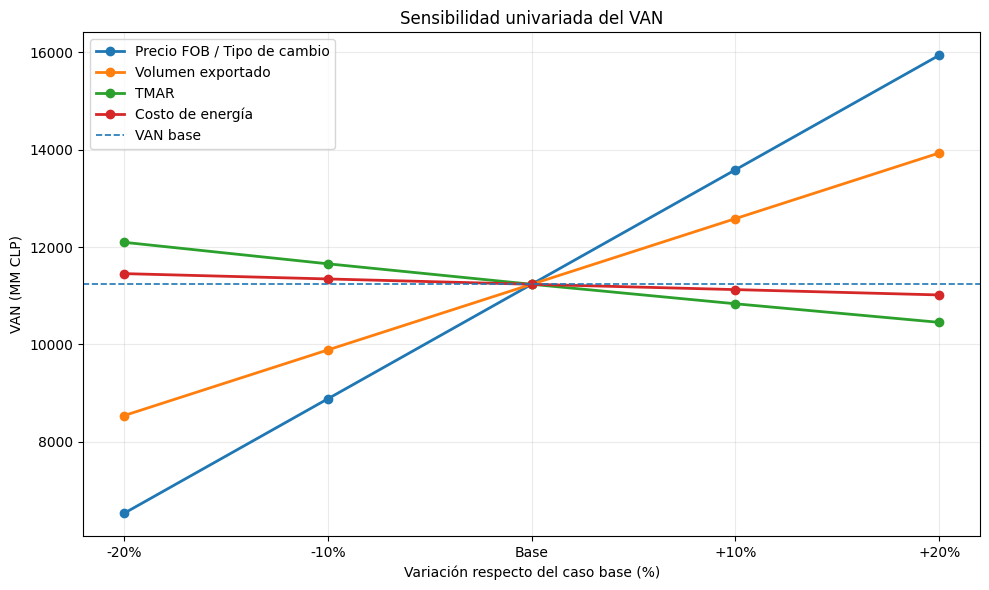

In [7]:


variaciones_pct = np.array([-20, -10, 0, 10, 20])

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    variaciones_pct,
    tabla_sensibilidad["Precio FOB"].values,
    marker="o",
    linewidth=2,
    label="Precio FOB / Tipo de cambio"
)

ax.plot(
    variaciones_pct,
    tabla_sensibilidad["Volumen exportado"].values,
    marker="o",
    linewidth=2,
    label="Volumen exportado"
)

ax.plot(
    variaciones_pct,
    tabla_sensibilidad["TMAR"].values,
    marker="o",
    linewidth=2,
    label="TMAR"
)

ax.plot(
    variaciones_pct,
    tabla_sensibilidad["Costo de energía"].values,
    marker="o",
    linewidth=2,
    label="Costo de energía"
)

ax.axhline(
    van_base,
    linestyle="--",
    linewidth=1.2,
    label="VAN base"
)

ax.set_title("Sensibilidad univariada del VAN")
ax.set_xlabel("Variación respecto del caso base (%)")
ax.set_ylabel("VAN (MM CLP)")

ax.set_xticks(variaciones_pct)
ax.set_xticklabels(
    ["-20%", "-10%", "Base", "+10%", "+20%"]
)

ax.grid(True, alpha=0.25)
ax.legend()

fig.tight_layout()

# IMPORTANTE: guardar la figura explícitamente con fig.savefig()
fig.savefig(
    "sensibilidad_univariada.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Tornado
El tornado utiliza los resultados de \(-20\%\) y \(+20\%\) para cada variable. Las variables se ordenan según la amplitud total de su efecto sobre el VAN.

Los valores numéricos no se escriben junto a las etiquetas del eje vertical, ya que esos valores ya se encuentran en la tabla de sensibilidad. De esta manera se evita el solapamiento y se mantiene el gráfico legible.


,Variable,VAN mínimo,VAN máximo,Rango
0,Tipo de cambio,6531.6435,15937.8810,9406.2376
1,Precio FOB,6531.6435,15937.8810,9406.2376
2,Volumen exportado,8538.3487,13931.1758,5392.8270
3,TMAR,10452.8502,12096.9054,1644.0552
4,Costo de energía,11015.8490,11453.6756,437.8266


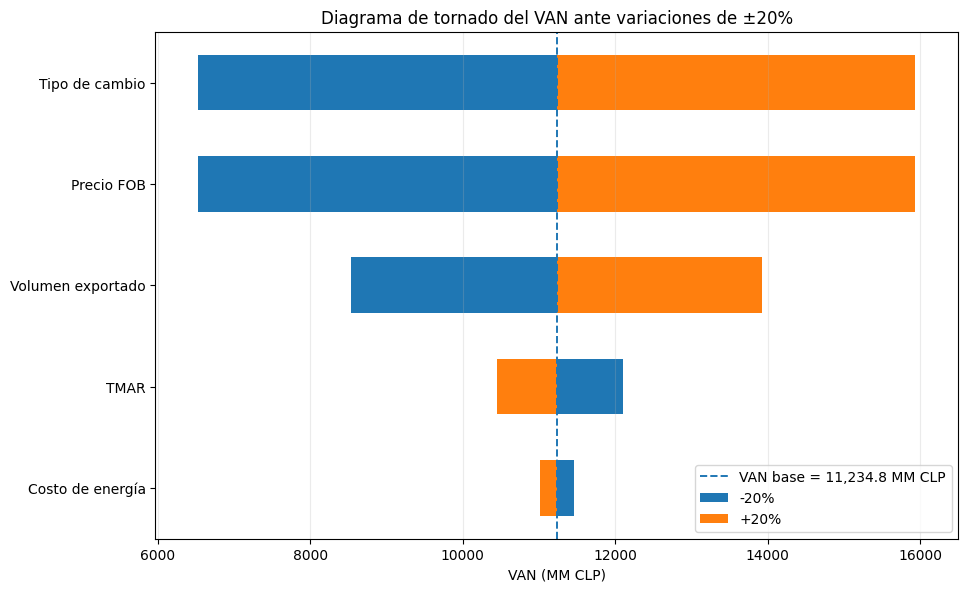

In [9]:

variables = np.array([
    "Precio FOB",
    "Tipo de cambio",
    "Volumen exportado",
    "TMAR",
    "Costo de energía"
])

# VAN ante -20% y +20%
van_menos20 = np.array([
    tabla_sensibilidad.loc["-20%", "Precio FOB"],
    tabla_sensibilidad.loc["-20%", "Tipo de cambio"],
    tabla_sensibilidad.loc["-20%", "Volumen exportado"],
    tabla_sensibilidad.loc["-20%", "TMAR"],
    tabla_sensibilidad.loc["-20%", "Costo de energía"]
])

van_mas20 = np.array([
    tabla_sensibilidad.loc["+20%", "Precio FOB"],
    tabla_sensibilidad.loc["+20%", "Tipo de cambio"],
    tabla_sensibilidad.loc["+20%", "Volumen exportado"],
    tabla_sensibilidad.loc["+20%", "TMAR"],
    tabla_sensibilidad.loc["+20%", "Costo de energía"]
])

# Rango total generado por cada variable
van_minimo = np.minimum(van_menos20, van_mas20)
van_maximo = np.maximum(van_menos20, van_mas20)
rangos = van_maximo - van_minimo

# Ordenar de mayor a menor impacto
orden = np.argsort(rangos)[::-1]

variables = variables[orden]
van_menos20 = van_menos20[orden]
van_mas20 = van_mas20[orden]
van_minimo = van_minimo[orden]
van_maximo = van_maximo[orden]
rangos = rangos[orden]

# Tabla de ranking
tabla_tornado = pd.DataFrame({
    "Variable": variables,
    "VAN mínimo": van_minimo,
    "VAN máximo": van_maximo,
    "Rango": rangos
})

display(tabla_tornado.round(4))




y = np.arange(len(variables))

fig, ax = plt.subplots(figsize=(11, 6.5))

# Barra correspondiente a -20%
inicio_menos20 = np.minimum(van_base, van_menos20)

ax.barh(
    y,
    np.abs(van_menos20 - van_base),
    left=inicio_menos20,
    height=0.55,
    label="-20%"
)

# Barra correspondiente a +20%
inicio_mas20 = np.minimum(van_base, van_mas20)

ax.barh(
    y,
    np.abs(van_mas20 - van_base),
    left=inicio_mas20,
    height=0.55,
    label="+20%"
)

# VAN base
ax.axvline(
    van_base,
    linestyle="--",
    linewidth=1.4,
    label=f"VAN base = {van_base:,.1f} MM CLP"
)

ax.set_yticks(y)
ax.set_yticklabels(variables)

# Mayor impacto arriba
ax.invert_yaxis()

ax.set_xlabel("VAN (MM CLP)")
ax.set_title(
    "Diagrama de tornado del VAN ante variaciones de ±20%"
)

ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right")

# Espacio suficiente para que no se corte ninguna etiqueta
rango_grafico = van_maximo.max() - van_minimo.min()

ax.set_xlim(
    van_minimo.min() - 0.06 * rango_grafico,
    van_maximo.max() + 0.06 * rango_grafico
)

fig.subplots_adjust(
    left=0.23,
    right=0.96,
    top=0.90,
    bottom=0.12
)

# Guardar ANTES de mostrar
fig.savefig(
    "tornado_sensibilidad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



El ranking se obtiene con la diferencia:

\[Rango_i=VAN_{i,\max}-VAN_{i,\min}.\]

Un rango mayor significa que el VAN es más sensible a esa variable.


In [10]:

ranking = tabla_tornado[["Variable", "Rango"]].copy()
ranking["Prioridad"] = np.arange(1, len(ranking) + 1)

display(ranking.round(4))


,Variable,Rango,Prioridad
0,Tipo de cambio,9406.2376,1
1,Precio FOB,9406.2376,2
2,Volumen exportado,5392.8270,3
3,TMAR,1644.0552,4
4,Costo de energía,437.8266,5
